# Reduce full-CLN setup and retained sparse operators

Follow-up to [notebook 25](25_cached_cln.ipynb). T and A retain separate boundary masks, scalar trace factorizations and local projections. Identical load/check matrices are shared inside one recursion after checking native element-to-global DOF layouts. The scalar load matrix targets only the HDiv flux component; zero scalar/trace rows are filled explicitly.

All three stages, seven fields and acceptance gates remain. See [the contract](COMPACT_CLN.md).

In [1]:
import json, statistics as st
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
base=Path('data') if Path('data').is_dir() else Path('docs/data')
data=json.loads((base/'compact_cln_timing.json').read_text())
host=json.loads((base/'compact_cln_host.json').read_text())
controls=json.loads((base/'compact_cln_controls.json').read_text())
memory=json.loads((base/'compact_cln_memory.json').read_text())
assert all(x['complete'] for x in (data,host,controls))
assert memory['complete'] is False and memory['status']=='interrupted_by_user_shutdown'
routes=['original','condensed','scalar-cached','scalar-compact','scalar-cached-mexcuda','scalar-compact-mexcuda']
labels=['A-T','Condensed A-T','Previous CPU','Compact CPU','Previous mexcuda','Compact mexcuda']
def warm(c,r):return [x for x in c['repeats'] if x['route']==r and x['repeat']>0]
def med(c,r,k='seconds'):return st.median(x[k] for x in warm(c,r))
def table(head,rows):display(Markdown(' | '.join(head)+'\n'+' | '.join(['---']*len(head))+'\n'+'\n'.join(' | '.join(map(str,row)) for row in rows)))
print(data['runtime']);print(data['matlab_engine'])
print('Foreign compute samples:',sum(bool(x) for x in host['foreign_compute_job_samples']))


{'host': 'NGSolve', 'python': '3.12.10', 'ngsolve': '6.2.2607', 'numpy': '2.5.2', 'radia': '5.2.3', 'threads': 4, 'blas_pools': [{'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.34.0.0', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'openblas', 'version': '0.3.33', 'threading_layer': 'pthreads', 'architecture': 'Haswell'}, {'user_api': 'blas', 'internal_api': 'mkl', 'num_threads': 1, 'prefix': 'mkl_rt', 'version': '2026.1-Product', 'threading_layer': 'intel'}, {'user_api': 'blas', 'internal_api': 'openblas', 'num_threads': 1, 'prefix': 'libscipy_openblas', 'version': '0.3.31.dev', 'threading_layer': 'pthreads', 'architecture': 'SkylakeX'}, {'user_api': 'openmp', 'internal_api': 'openmp', 'num_threads': 18, 'prefix': 'libiomp', 'version': None}]}
{'start_seconds': 6.550061199999618, 'version': '26.1.0.3203278 (R2026a)', 'binary_sha25

## Matched complete recursion

Each route has one first observation and three warmed repeats. Order reverses on alternating repeats. Timing includes setup, transfer, all seven advances and mandatory checks. Engine/device initialization is reported separately. Imports, mesh generation, cross-route comparisons, reporting samples, destruction and Engine shutdown are outside each solver timer. The host wrapper retains whole-experiment time.

Cohort | A-T | Condensed A-T | Previous CPU | Compact CPU | Previous mexcuda | Compact mexcuda
--- | --- | --- | --- | --- | --- | ---
p=2, h=3 mm | 1.2055 | 1.1419 | 2.5156 | 2.5011 | 2.1771 | 2.4080
p=3, h=3 mm | 3.3327 | 2.2864 | 5.7522 | 5.4909 | 5.1336 | 4.7663
p=3, h=2 mm | 8.7592 | 6.3413 | 18.5026 | 17.5637 | 14.1726 | 13.1610
p=4, h=3 mm | 8.7001 | 4.5173 | 15.5721 | 13.9335 | 13.7422 | 11.8714

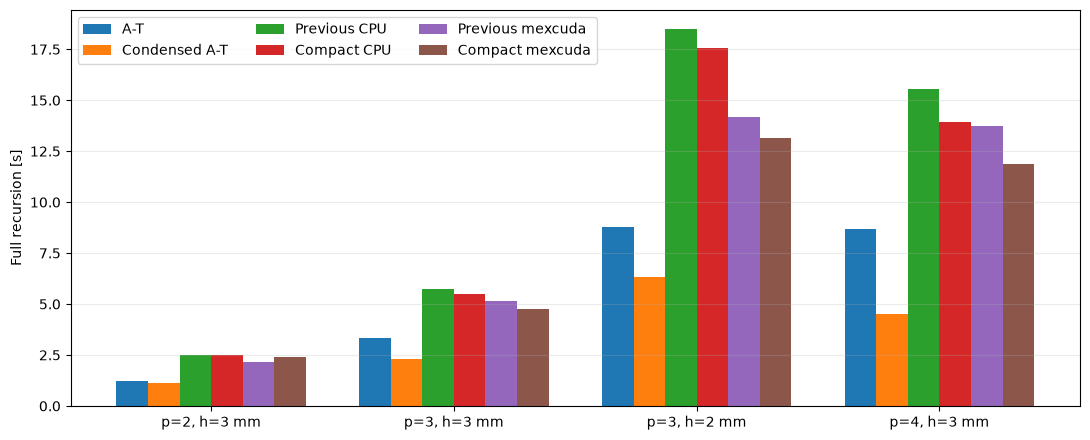

Cohort | Route | First [s] | Warm min | Warm median | Warm max
--- | --- | --- | --- | --- | ---
p=2, h=3 mm | original | 3.9976 | 1.1564 | 1.2055 | 1.4228
p=2, h=3 mm | condensed | 1.0748 | 1.1011 | 1.1419 | 1.2143
p=2, h=3 mm | scalar-cached | 2.3328 | 2.3820 | 2.5156 | 2.5475
p=2, h=3 mm | scalar-compact | 2.4542 | 2.4308 | 2.5011 | 2.5591
p=2, h=3 mm | scalar-cached-mexcuda | 2.2023 | 2.0960 | 2.1771 | 2.2412
p=2, h=3 mm | scalar-compact-mexcuda | 2.6128 | 2.3224 | 2.4080 | 2.5108
p=3, h=3 mm | original | 3.4245 | 3.1699 | 3.3327 | 3.7808
p=3, h=3 mm | condensed | 2.3088 | 2.2444 | 2.2864 | 2.4450
p=3, h=3 mm | scalar-cached | 5.6532 | 5.7507 | 5.7522 | 5.7803
p=3, h=3 mm | scalar-compact | 5.4998 | 5.4486 | 5.4909 | 5.5041
p=3, h=3 mm | scalar-cached-mexcuda | 5.1340 | 5.0929 | 5.1336 | 5.1636
p=3, h=3 mm | scalar-compact-mexcuda | 4.8712 | 4.7532 | 4.7663 | 4.9401
p=3, h=2 mm | original | 8.6083 | 8.4451 | 8.7592 | 9.2171
p=3, h=2 mm | condensed | 6.6306 | 6.2611 | 6.3413 | 7.1096
p=3, h=2 mm | scalar-cached | 18.7069 | 18.4499 | 18.5026 | 18.8192
p=3, h=2 mm | scalar-compact | 17.3375 | 17.3963 | 17.5637 | 17.6406
p=3, h=2 mm | scalar-cached-mexcuda | 14.5671 | 14.0606 | 14.1726 | 14.2292
p=3, h=2 mm | scalar-compact-mexcuda | 13.1871 | 13.1056 | 13.1610 | 13.1716
p=4, h=3 mm | original | 8.6482 | 8.3655 | 8.7001 | 8.8342
p=4, h=3 mm | condensed | 4.5795 | 4.4851 | 4.5173 | 4.6522
p=4, h=3 mm | scalar-cached | 15.7019 | 15.5581 | 15.5721 | 15.6612
p=4, h=3 mm | scalar-compact | 13.8394 | 13.7355 | 13.9335 | 14.0239
p=4, h=3 mm | scalar-cached-mexcuda | 13.6843 | 13.6858 | 13.7422 | 13.8489
p=4, h=3 mm | scalar-compact-mexcuda | 11.9317 | 11.8368 | 11.8714 | 12.1308

In [2]:
rows=[];names=[];values=[]
for c in data['cohorts']:
 name=f"p={c['order']}, h={c['maxh']*1000:g} mm";names.append(name)
 times=[med(c,r) for r in routes];values.append(times)
 rows.append([name]+[f'{x:.4f}' for x in times])
table(['Cohort']+labels,rows)
fig,ax=plt.subplots(figsize=(11,4.5));x=np.arange(len(names));w=.13
for j,label in enumerate(labels):ax.bar(x+(j-2.5)*w,np.array(values)[:,j],w,label=label)
ax.set_xticks(x,names);ax.set_ylabel('Full recursion [s]');ax.legend(ncol=3);ax.grid(axis='y',alpha=.25)
fig.tight_layout();plt.show()
rows=[]
for c,name in zip(data['cohorts'],names):
 for route in routes:
  times=[r['seconds'] for r in warm(c,route)]
  first=next(r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']==0)
  rows.append([name,route]+[f'{v:.4f}' for v in (first,min(times),st.median(times),max(times))])
table(['Cohort','Route','First [s]','Warm min','Warm median','Warm max'],rows)


## Setup and extra CSR storage

CSR counts refer to unique retained operators in the compact route, counting shared T/A matrices once. Previous counts include both independent role copies. These are logical CSR arrays; native graphs, factorization, local dense projection arrays, MATLAB and GPU allocations are separate. No cache survives a complete run.

In [3]:
rows=[]
for c,name in zip(data['cohorts'],names):
 old=warm(c,'scalar-cached')[0];new=warm(c,'scalar-compact')[0]
 a=sum(old['cached_operator_csr_bytes_by_role'].values());b=sum(new['unique_operator_csr_bytes'].values())
 rows.append([name]+[f'{med(c,r,"setup_seconds"):.4f}' for r in routes[2:]]+[f'{a/2**20:.2f}',f'{b/2**20:.2f}',f'{100*(1-b/a):.1f}%'])
table(['Cohort','Previous CPU setup','Compact CPU setup','Previous MEX setup','Compact MEX setup','Previous MiB','Compact MiB','CSR reduction'],rows)
rows=[]
for c,name in zip(data['cohorts'],names):
 for key in warm(c,'scalar-compact')[0]['unique_operator_csr_bytes']:
  samples=warm(c,'scalar-compact')
  rows.append([name,key,f"{st.median(r['operator_assembly_seconds'][key] for r in samples):.5f}",f"{samples[0]['unique_operator_csr_bytes'][key]/2**20:.2f}"])
table(['Cohort','Operator','Assembly median [s]','Unique MiB'],rows)


Cohort | Previous CPU setup | Compact CPU setup | Previous MEX setup | Compact MEX setup | Previous MiB | Compact MiB | CSR reduction
--- | --- | --- | --- | --- | --- | --- | ---
p=2, h=3 mm | 1.4211 | 1.4046 | 1.3022 | 1.5298 | 27.69 | 11.90 | 57.0%
p=3, h=3 mm | 3.6541 | 3.3756 | 3.7652 | 3.3813 | 136.82 | 59.74 | 56.3%
p=3, h=2 mm | 10.2742 | 9.1461 | 10.6804 | 9.6951 | 404.33 | 176.63 | 56.3%
p=4, h=3 mm | 10.6086 | 8.8143 | 11.1305 | 9.2750 | 476.69 | 210.57 | 55.8%

Cohort | Operator | Assembly median [s] | Unique MiB
--- | --- | --- | ---
p=2, h=3 mm | original-scalar | 0.03706 | 3.64
p=2, h=3 mm | scalar-load | 0.04129 | 2.15
p=2, h=3 mm | recovery-load | 0.05060 | 2.22
p=2, h=3 mm | physical-curl_load | 0.03297 | 1.00
p=2, h=3 mm | physical-force_load | 0.01970 | 1.00
p=2, h=3 mm | physical-curl_check | 0.03847 | 1.89
p=3, h=3 mm | original-scalar | 0.11772 | 19.46
p=3, h=3 mm | scalar-load | 0.10791 | 10.62
p=3, h=3 mm | recovery-load | 0.13591 | 10.74
p=3, h=3 mm | physical-curl_load | 0.09452 | 5.14
p=3, h=3 mm | physical-force_load | 0.07205 | 5.14
p=3, h=3 mm | physical-curl_check | 0.14014 | 8.64
p=3, h=2 mm | original-scalar | 0.29558 | 57.57
p=3, h=2 mm | scalar-load | 0.27118 | 31.45
p=3, h=2 mm | recovery-load | 0.39042 | 31.80
p=3, h=2 mm | physical-curl_load | 0.27201 | 15.21
p=3, h=2 mm | physical-force_load | 0.21703 | 15.21
p=3, h=2 mm | physical-curl_check | 0.42238 | 25.38
p=4, h=3 mm | original-scalar | 0.32350 | 69.98
p=4, h=3 mm | scalar-load | 0.33595 | 37.00
p=4, h=3 mm | recovery-load | 0.46851 | 37.18
p=4, h=3 mm | physical-curl_load | 0.28402 | 18.69
p=4, h=3 mm | physical-force_load | 0.25458 | 18.69
p=4, h=3 mm | physical-curl_check | 0.45666 | 29.03

## Interrupted native memory audit

Formal timing and precision results were recovered completely. During the separate fresh-process CPU memory lane, the user shut down the metered NGSolve VM. Six console peak-working-set observations were received; full worker records and private-commit counters were not recovered. The partial observations below are not a completed whole-process memory comparison. Additional CSR storage is fully measured in all four formal cohorts above. p=3/p=4 and mexcuda whole-method peak-memory advantages remain unverified.

The job-owned remote scratch is retained pending recovery and deletion when the user next starts the VM; this task does not start the VM.

In [4]:
rows=[]
for case in memory['observed_console_peaks']:
 rows.append([f"p={case['order']}, h={case['maxh']*1000:g} mm",case['route'],f"{case['peak_working_set_mib']:.2f}"])
table(['Cohort','Route','Console lifetime peak RSS MiB'],rows)
print('Audit status:',memory['status'])
print('Pending:',memory['pending'])

Cohort | Route | Console lifetime peak RSS MiB
--- | --- | ---
p=2, h=3 mm | original | 170.71
p=2, h=3 mm | condensed | 151.42
p=2, h=3 mm | scalar-cached | 193.12
p=2, h=3 mm | scalar-compact | 177.02
p=3, h=3 mm | original | 230.54
p=3, h=3 mm | condensed | 197.01

Audit status: interrupted_by_user_shutdown
Pending: Recover remote partial memory records and job-owned scratch when the user next starts the VM. Do not infer p3/p4 or mexcuda whole-method memory advantage.


## Unchanged precision gates

Original uncompiled load/check vectors are independently compared for flat and curved meshes, p=2–4, both boundary roles and three scale/sign/buffer updates. Explicit original LinearForm quadrature and direct order-13 curl-field integration are retained. Global vector solves remain forbidden on scalar routes.

In [5]:
comparisons=[x for c in data['cohorts'] for x in c['comparisons'] if 'compact' in x['route']]
steps=[s for c in data['cohorts'] for r in c['repeats'] if 'compact' in r['route'] for s in r['solves']]
print('Coefficient relative difference:',max(abs(v) for x in comparisons for v in x['relative_coefficients']))
print('Volume-vector relative difference:',max(v for x in comparisons for v in x['volume_relative_field_errors']))
for key in ('scalar_trace_residual','original_scalar_residual','original_physical_residual','recovered_original_residual','relative_divergence','curl_fit_residual','relative_curl_field_error'):
 print(key,max(s[key] for s in steps))
print('Independent control cases:',len(controls['cases']))
print('Maximum native vector difference:',max(max(x['physical_vector_relative_errors']+x['scalar_load_relative_errors']+[x['curl_load_relative_error'],x['scalar_operator_relative_error']]) for x in controls['cases']))
print('Global vector solves:',sorted({s['global_vector_solves'] for s in steps}))


Coefficient relative difference: 1.2116718739463295e-10
Volume-vector relative difference: 5.3499895820301645e-09
scalar_trace_residual 8.336695691724204e-14
original_scalar_residual 1.5179518095729252e-14
original_physical_residual 6.402551919783649e-11
recovered_original_residual 4.199705385527952e-10
relative_divergence 1.5500284973413497e-13
curl_fit_residual 9.760434199353318e-11
relative_curl_field_error 9.760636097980787e-11
Independent control cases: 12
Maximum native vector difference: 6.665663090448446e-16
Global vector solves: [0]


Scope: homogeneous, simply connected, zero-shift internal wire with curved tetrahedra. Same-mesh parity does not establish FEM convergence or universal A-T superiority. C2 independent T–Omega validation, loss FEM convergence and F2/Radia API migration remain open. Runtime is released Radia 5.2.3 plus hash-identified validation sources and the unchanged MEX binary.